In [5]:
import tensorflow as tf
from keras import Sequential
from keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist

import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [6]:

# Chargement du dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalisation des pixels
x_train = x_train / 255.0
x_test = x_test / 255.0

# Dimensions des données
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)


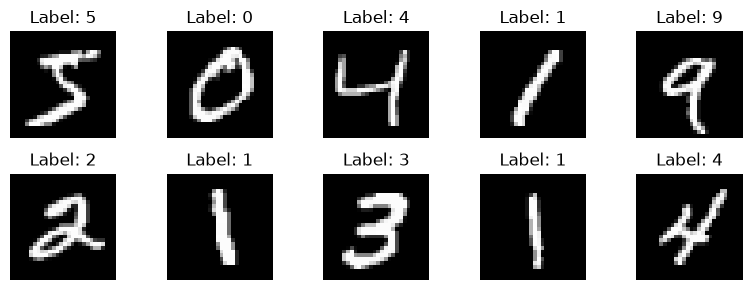

In [7]:

plt.figure(figsize=(8, 3))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [8]:

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9275 - loss: 0.2554 - val_accuracy: 0.9612 - val_loss: 0.1313
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9661 - loss: 0.1138 - val_accuracy: 0.9708 - val_loss: 0.0915
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9764 - loss: 0.0778 - val_accuracy: 0.9691 - val_loss: 0.0967
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9823 - loss: 0.0584 - val_accuracy: 0.9775 - val_loss: 0.0684
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9862 - loss: 0.0444 - val_accuracy: 0.9776 - val_loss: 0.0725


In [12]:

test_loss, test_acc = model.evaluate(x_test, y_test)

print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9776 - loss: 0.0725
Test accuracy: 0.9776
Test loss: 0.0725


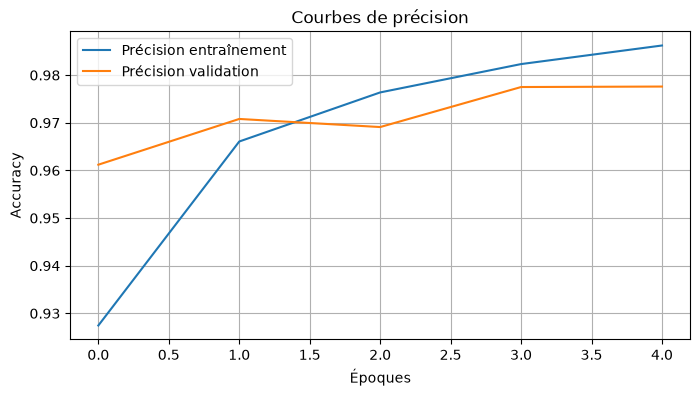

In [13]:

plt.figure(figsize=(8, 4))

plt.plot(history.history['accuracy'],
         label='Précision entraînement')

plt.plot(history.history['val_accuracy'],
         label='Précision validation')

plt.title("Courbes de précision")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


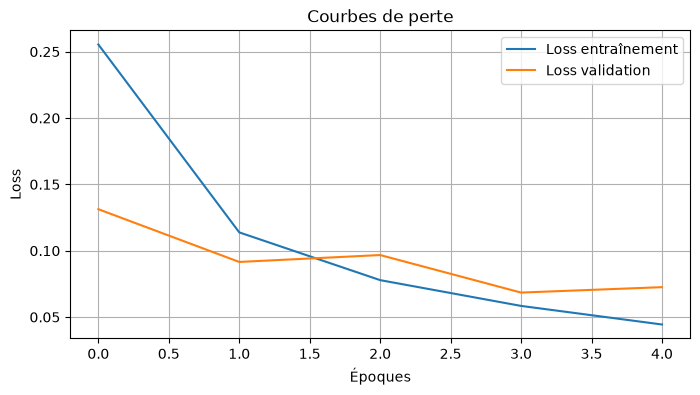

In [14]:

plt.figure(figsize=(8, 4))

plt.plot(history.history['loss'],
         label='Loss entraînement')

plt.plot(history.history['val_loss'],
         label='Loss validation')

plt.title("Courbes de perte")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 872us/step


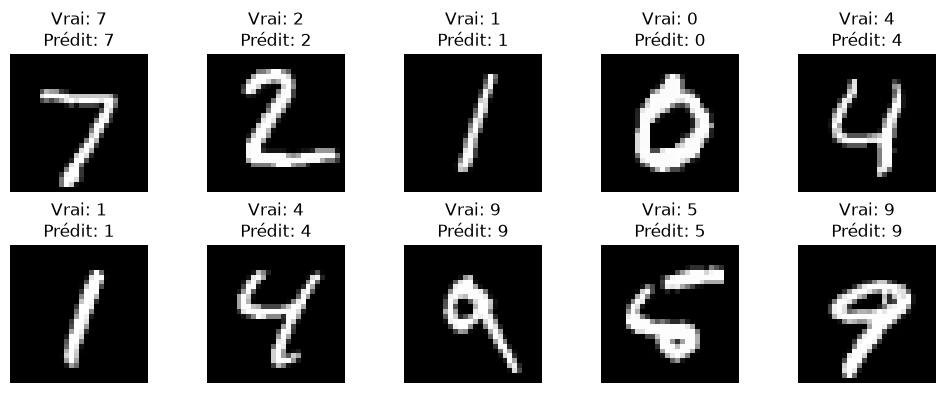

In [15]:

# Effectuer les prédictions
predictions = model.predict(x_test)

# Afficher les 10 premières images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap='gray')

    plt.title(
        f"Vrai: {y_test[i]}\n"
        f"Prédit: {np.argmax(predictions[i])}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()


Nombre d'erreurs : 224


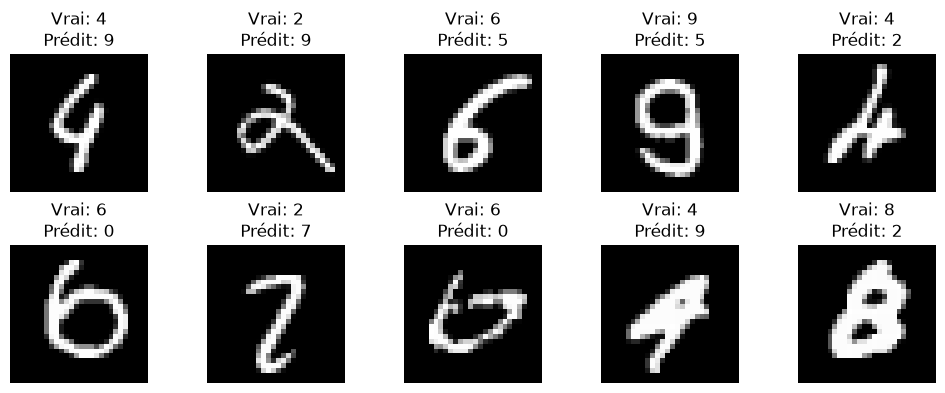

In [16]:

# Récupérer les chiffres prédits
y_pred = np.argmax(predictions, axis=1)

# Trouver les indices des erreurs
errors = np.where(y_pred != y_test)[0]

print("Nombre d'erreurs :", len(errors))

# Afficher les 10 premières erreurs
plt.figure(figsize=(10, 4))

for i, idx in enumerate(errors[:10]):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[idx], cmap='gray')

    plt.title(
        f"Vrai: {y_test[idx]}\n"
        f"Prédit: {y_pred[idx]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()
